In [1]:
import csv
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

with open("chinese_mnist.csv", encoding="utf-8-sig") as file:
    rows = list(csv.DictReader(file))

def load_image(row):
    path = f"data/input_{row['suite_id']}_{row['sample_id']}_{row['code']}.jpg"
    with Image.open(path) as image:
        return np.array(image.convert("L"))


In [2]:
def preprocess(image):
    y, x = np.where(image > 30)
    if len(x) == 0:
        raise ValueError("Empty image")

    image = image[y.min():y.max() + 1, x.min():x.max() + 1]
    height, width = image.shape
    scale = 56 / max(height, width)
    width = max(1, round(width * scale))
    height = max(1, round(height * scale))
    image = Image.fromarray(image).resize((width, height), Image.Resampling.BILINEAR)

    result = np.zeros((64, 64), dtype=np.float32)
    x = (64 - width) // 2
    y = (64 - height) // 2
    result[y:y + height, x:x + width] = np.array(image)
    return result / result.max()


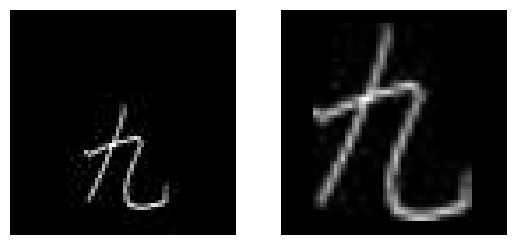

In [3]:
image = load_image(rows[0])

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(preprocess(image), cmap="gray")
plt.axis("off")
plt.show()


In [4]:
images = []
labels = []
writer_ids = []
characters = ["一", "二", "三", "四", "五", "六", "七", "八", "九", "十"]

for row in rows:
    digit = int(row["value"])
    if 1 <= digit <= 10:
        images.append(preprocess(load_image(row)))
        labels.append(digit - 1)
        writer_ids.append(int(row["suite_id"]))

X = np.array(images).reshape(-1, 4096)
y = np.array(labels)
writer_ids = np.array(writer_ids)


In [16]:
from sklearn.model_selection import train_test_split
train_writers, remaining_writers = train_test_split(
    np.unique(writer_ids), test_size=0.2, random_state=42
)
val_writers, test_writers = train_test_split(
    remaining_writers, test_size=0.5, random_state=42
)

train = np.isin(writer_ids, train_writers)
val = np.isin(writer_ids, val_writers)
test = np.isin(writer_ids, test_writers)

X_train, y_train = X[train], y[train]
X_val, y_val = X[val], y[val]
X_test, y_test = X[test], y[test]


In [17]:
rng = np.random.default_rng(42)
hidden_size = 128
W1 = (rng.standard_normal((4096, hidden_size)) * np.sqrt(2 / 4096)).astype(np.float32)
b1 = np.zeros((1, hidden_size), dtype=np.float32)
W2 = (rng.standard_normal((hidden_size, 10)) * np.sqrt(1 / hidden_size)).astype(np.float32)
b2 = np.zeros((1, 10), dtype=np.float32)


In [18]:
def forward(X):
    hidden = np.maximum(0, X @ W1 + b1)
    scores = hidden @ W2 + b2
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    probs = exp_scores / exp_scores.sum(axis=1, keepdims=True)
    return hidden, scores, probs


In [8]:
def cross_entropy(scores, y):
    log_probs = scores - np.log(np.exp(scores).sum(axis=1, keepdims=True))
    return -log_probs[np.arange(len(y)), y].mean()


In [9]:
def backward(X, y, hidden, probs):
    batch_size = len(y)
    targets = np.zeros_like(probs)
    for i in range(batch_size):
        targets[i, y[i]] = 1

    d_scores = (probs - targets) / batch_size

    dW2 = hidden.T @ d_scores
    db2 = d_scores.sum(axis=0, keepdims=True)
    d_hidden = d_scores @ W2.T


    d_hidden[hidden <= 0] = 0
    dW1 = X.T @ d_hidden
    db1 = d_hidden.sum(axis=0, keepdims=True)

    return dW1, db1, dW2, db2


In [19]:
epochs = 40
batch_size = 64
learning_rate = 0.01

for epoch in range(epochs):
    indices = rng.permutation(len(X_train))

    for start in range(0, len(X_train), batch_size):
        batch = indices[start:start + batch_size]
        X_batch, y_batch = X_train[batch], y_train[batch]

        hidden, scores, probs = forward(X_batch)
        dW1, db1, dW2, db2 = backward(X_batch, y_batch, hidden, probs)

        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1
        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

    if (epoch + 1) % 10 == 0:
        _, scores, probs = forward(X_val)
        loss = cross_entropy(scores, y_val)
        accuracy = (probs.argmax(axis=1) == y_val).mean()
        print(f"{epoch + 1}: loss {loss:.3f}, accuracy {accuracy:.1%}")


10: loss 0.240, accuracy 95.9%
20: loss 0.149, accuracy 97.6%
30: loss 0.118, accuracy 97.8%
40: loss 0.103, accuracy 97.9%


In [20]:
_, _, probs = forward(X_test)
predictions = probs.argmax(axis=1)
accuracy = (predictions == y_test).mean()
print(f"Test accuracy: {accuracy:.1%}")


Test accuracy: 96.0%


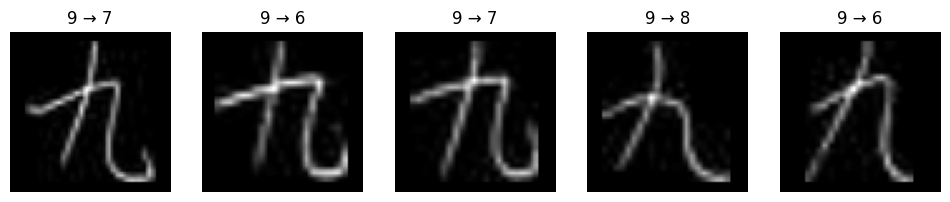

In [21]:
wrong = np.where(predictions != y_test)[0][:5]

if len(wrong) > 0:
    plt.figure(figsize=(12, 3))
    for plot, i in enumerate(wrong):
        plt.subplot(1, len(wrong), plot + 1)
        plt.imshow(X_test[i].reshape(64, 64), cmap="gray")
        plt.title(f"{y_test[i] + 1} → {predictions[i] + 1}")
        plt.axis("off")
    plt.show()


In [22]:
import tkinter as tk
from PIL import ImageDraw, ImageTk

names = [
    "Coyote Starrk", "Baraggan Louisenbairn", "Nelliel Tu Odelschwanck",
    "Ulquiorra Cifer", "Nnoitra Gilga", "Grimmjow Jaegerjaquez",
    "Zommari Rureaux", "Szayelaporro Granz", "Aaroniero Arruruerie", "Yammy Llargo"
]

size = 320
drawing = Image.new("L", (size, size), 0)
pen = ImageDraw.Draw(drawing)
last_point = None

root = tk.Tk()
root.title("Chinese Digits - Espadas")
root.minsize(360, 500)

draw_frame = tk.Frame(root)
draw_frame.pack(padx=16, pady=12)
tk.Label(draw_frame, text="Draw a Chinese number", font=("Arial", 14)).pack(pady=8)
canvas = tk.Canvas(draw_frame, width=size, height=size, bg="black", highlightthickness=0)
canvas.pack()
message = tk.StringVar()
tk.Label(draw_frame, textvariable=message).pack(pady=4)

result_frame = tk.Frame(root)
picture = tk.Label(result_frame)
picture.pack()
result = tk.StringVar()
tk.Label(result_frame, textvariable=result, font=("Arial", 16), wraplength=320).pack(pady=8)

def draw(event):
    global last_point
    message.set("")
    x, y = event.x, event.y
    if last_point is not None:
        canvas.create_line(*last_point, x, y, fill="white", width=12, capstyle=tk.ROUND)
        pen.line([last_point, (x, y)], fill=255, width=12)
    canvas.create_oval(x - 6, y - 6, x + 6, y + 6, fill="white", outline="")
    pen.ellipse((x - 6, y - 6, x + 6, y + 6), fill=255)
    last_point = (x, y)

def stop_drawing(event):
    global last_point
    last_point = None

def clear():
    global last_point
    last_point = None
    canvas.delete("all")
    pen.rectangle((0, 0, size, size), fill=0)
    message.set("")

def again():
    clear()
    result.set("")
    picture.config(image="")
    picture.image = None
    result_frame.pack_forget()
    draw_frame.pack(padx=16, pady=12)
    predict_button.focus_set()

def predict():
    image = np.array(drawing)
    if image.max() == 0:
        message.set("Draw first")
        return
    image = preprocess(image).reshape(1, -1)
    _, _, probs = forward(image)
    digit = probs.argmax() + 1

    with Image.open(f"Espadas/cropped/{digit}.png") as portrait:
        portrait.thumbnail((320, 350))
        picture.image = ImageTk.PhotoImage(portrait)
    picture.config(image=picture.image)
    result.set(f"{characters[digit - 1]} ({digit})\n{names[digit - 1]}")
    draw_frame.pack_forget()
    result_frame.pack(padx=16, pady=12)
    again_button.focus_set()

canvas.bind("<Button-1>", draw)
canvas.bind("<B1-Motion>", draw)
canvas.bind("<ButtonRelease-1>", stop_drawing)

buttons = tk.Frame(draw_frame)
buttons.pack()
predict_button = tk.Button(buttons, text="Predict", command=predict, width=12, pady=8)
predict_button.pack(side="left", padx=4)
tk.Button(buttons, text="Clear", command=clear, width=12, pady=8).pack(side="left", padx=4)
again_button = tk.Button(result_frame, text="Again", command=again, width=12, pady=8)
again_button.pack(pady=8)

root.mainloop()
